# Exploración documental y extracción verificable de narrativas

## Propósito y unidad de presentación

Recupero retrasos/soluciones y avances/logros del PDF oficial del corte seleccionado. Reconstruyo los reportes de entidad, meta e indicador con sus continuaciones entre páginas y después preparo una fila por meta producto.

Distingo disponibilidad del PDF, conservación de palabras, asignación de contexto y cobertura de indicadores. Ninguna de esas comprobaciones certifica la veracidad de una declaración institucional. No resumo relatos, completo frases ni realizo codificación temática en esta etapa.

**Lectura de los resultados.** La metodología describe el procedimiento para cualquier corte compatible. Los resúmenes que aparecen al ejecutar las celdas describen exclusivamente la fuente seleccionada. Para actualizar el estudio ejecuto el notebook desde el inicio; las salidas guardadas no se actualizan por abrir el archivo. Mantengo las revisiones anteriores en un anexo histórico, sin atribuirlas al corte actual.



In [1]:
# Si faltan dependencias, descomentar y ejecutar:
# %pip install pymupdf pandas pypdf

## 1. Cómo selecciono el PDF que voy a procesar

Localizo un PDF cuyo contenido confirme reporte por entidades, corte y campos narrativos, sin depender de que el nombre contenga el plural `entidades`. Si no indico un corte, utilizo el corte local común con Excel de las dos fuentes. Si ese periodo todavía no tiene PDF, omito esta etapa opcional e informo la ausencia, sin utilizar un documento anterior ni escribir resultados narrativos de otro corte. Un PDF ambiguo o incompatible sigue requiriendo revisión.

Calculo la huella del documento y conservo Bronce. Si hay varios contenidos distintos que cumplen el criterio, exijo resolver la versión. Esta decisión evita que un cambio en el nombre del archivo o una publicación duplicada cambien la fuente sin quedar advertidos.


In [2]:
from pathlib import Path
from datetime import date, datetime, timezone
from collections import Counter, defaultdict
from tempfile import NamedTemporaryFile
import csv
import hashlib
import re
import unicodedata
import pandas as pd
import pymupdf
from pypdf import PdfReader
from IPython.display import display, Markdown, Image

# Buscar la carpeta del proyecto, también al abrir un notebook desde una subcarpeta.
import os
import sys
sys.dont_write_bytecode = True
_carpeta_indicada = os.environ.get("PROYECTO_RAIZ")
_candidatas = ([Path(_carpeta_indicada).expanduser().resolve()] if _carpeta_indicada
               else [Path.cwd().resolve(), *Path.cwd().resolve().parents])
RAIZ = next((p for p in _candidatas if (p / "rutas.py").is_file()
             and (p / "01_descarga_ultimo_corte.ipynb").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("Abre Jupyter desde la carpeta del proyecto.")
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))
from rutas import raiz_proyecto, corte_local_comun
RAIZ = raiz_proyecto()
CORTE = None  # None o una fecha exacta: "2026-06-30".
ARCHIVO_PDF = None  # None o el nombre exacto cuando exista más de una versión.
VERIFICAR_CON_PYPDF = True
BRONCE = RAIZ / "Capa Bronce"
COLUMNAS = ["PLAN_META_PRODUCTO_CODIGO", "PLAN_INDICADOR_CODIGO",
            "RETRASOS_Y_SOLUCIONES", "AVANCES_Y_LOGROS"]
COLUMNAS_SALIDA = ["PLAN_META_PRODUCTO_CODIGO", "RETRASOS_Y_SOLUCIONES", "AVANCES_Y_LOGROS"]
ETIQUETAS = {"Retrasos y soluciones:": "RETRASOS_Y_SOLUCIONES",
             "Avances y Logros:": "AVANCES_Y_LOGROS"}

def seleccionar_pdf(base, corte=None, nombre=None):
    fecha = date.fromisoformat(corte if corte else corte_local_comun(RAIZ))
    carpeta = base / fecha.isoformat() / "gestion_inversion"
    candidatos = sorted(carpeta.glob("*.pdf"))
    if nombre:
        candidatos = [p for p in candidatos if p.name == nombre]
    if not candidatos:
        return None, fecha
    reconocidos = {}
    for ruta in candidatos:
        with pymupdf.open(ruta) as doc:
            texto = " ".join(doc[i].get_text() for i in range(min(2,len(doc))))
        cabecera = texto_limpio_pdf(texto)
        if fecha.strftime("%d/%m/%Y") not in cabecera:
            continue
        if "reporte de gestion e inversion por entidad" in cabecera and "avances y logros" in cabecera and "retrasos y soluciones" in cabecera:
            reconocidos.setdefault(hashlib.sha256(ruta.read_bytes()).hexdigest(),ruta)
    if len(reconocidos) != 1:
        raise ValueError(f"Se requiere un PDF por entidades del corte {fecha}; encontrados {list(reconocidos.values())}. No uso un PDF anterior silenciosamente.")
    return next(iter(reconocidos.values())), fecha


def texto_limpio_pdf(texto):
    normal = unicodedata.normalize("NFKD", texto.casefold())
    return " ".join("".join(c for c in normal if not unicodedata.combining(c)).split())

FUENTE, FECHA = seleccionar_pdf(BRONCE, CORTE, ARCHIVO_PDF)
HUELLA = hashlib.sha256(FUENTE.read_bytes()).hexdigest() if FUENTE is not None else None
DESTINO = RAIZ / "Capa Silver" / FECHA.isoformat() / "gestion_inversion"
RUTA_CSV = DESTINO / "gestion_inversion_narrativas.csv"
print("PDF:", FUENTE.relative_to(RAIZ) if FUENTE is not None else "No disponible para el corte; omito la etapa narrativa.")
print("Corte:", FECHA, "| SHA-256:", HUELLA)

PDF: Capa Bronce\2026-06-30\gestion_inversion\planacciongestioninversion20260630_entidades_a2ddd1077b.pdf
Corte: 2026-06-30 | SHA-256: c473c0b452ddf172d03af549ae7f86ca8315247cfaeed9090f8b7b27c61865b3


## 2. Reconocimiento de la estructura visual

El orden del texto extraído puede diferir del orden visual. Por ello reconozco coordenadas, metas, indicadores, etiquetas y cuerpos narrativos mediante los perfiles implementados. Una coincidencia entre dos palabras no basta para asignar un relato.

Recorro todas las páginas para comprobar texto, corte, plan y encabezados. Cuento etiquetas por posición, distinguiéndolas de las menciones dentro de la narrativa. Ante un diseño no reconocido detengo la lectura; no atribuyo compatibilidad automática a un PDF nuevo.



In [3]:
if FUENTE is not None:
    def texto_limpio(texto):
        return " ".join(unicodedata.normalize("NFC", texto).split())
    
    def lineas_visuales(pagina):
        resultado = []
        for bloque_id, bloque in enumerate(pagina.get_text("dict")["blocks"]):
            for linea_id, linea in enumerate(bloque.get("lines", [])):
                texto = "".join(s["text"] for s in linea["spans"]).strip()
                rect = pymupdf.Rect(linea["bbox"]) * pagina.rotation_matrix
                if texto:
                    resultado.append({"texto": texto, "rect": list(rect), "id": [bloque_id, linea_id]})
        return sorted(resultado, key=lambda l: (round(l["rect"][1], 1), l["rect"][0]))
    
    paginas = []
    inventario = []
    with pymupdf.open(FUENTE) as documento:
        for numero, pagina in enumerate(documento, start=1):
            texto = pagina.get_text()
            if not texto.strip():
                raise ValueError(f"Página {numero} sin texto: requiere OCR y revisión; no se omite.")
            if not any(abs(pagina.rect.width-w)<1 and abs(pagina.rect.height-h)<1 for w,h in [(7320,2000),(1620,1500)]):
                raise ValueError(f"Cambió el tamaño visual de la página {numero}; revisar coordenadas.")
            cortes = re.findall(r"Fecha de Corte:\s*(\d{2}/\d{2}/\d{4})", texto)
            if cortes != [FECHA.strftime("%d/%m/%Y")]:
                raise ValueError(f"Corte ausente, ambiguo o discordante en página {numero}: {cortes}")
            planes = re.findall(r"Plan de Desarrollo Distrital:\s*(\d+)\s*-", texto)
            if len(planes) != 1:
                raise ValueError(f"No se identifica un único plan en la página {numero}.")
            lineas = lineas_visuales(pagina)
            encabezados_entidad = [l for l in lineas if l["rect"][1] < 160
                                   and re.match(r"^\d{4}-", l["texto"])]
            if len(encabezados_entidad) > 1:
                raise ValueError(f"Entidad ambigua en la página {numero}.")
            entidad = encabezados_entidad[0]["texto"].split("-", 1)[0] if encabezados_entidad else None
            etiquetas = sum(l["texto"] in ETIQUETAS and abs(l["rect"][0]-18)<=2.5 and 245<=l["rect"][1]<pagina.rect.height-180 for l in lineas)
            indicadores = sum(abs(l["rect"][0] - 48) < 2 and bool(re.match(r"^\d{4} - ", l["texto"])) for l in lineas)
            if entidad is None and (etiquetas or indicadores):
                raise ValueError(f"La página {numero} contiene datos sin un encabezado de entidad.")
            paginas.append({"numero": numero, "plan": planes[0], "entidad": entidad,
                            "lineas": lineas, "texto": texto, "fin_datos": pagina.rect.height-180})
            inventario.append({"pagina": numero, "entidad": entidad or "",
                               "caracteres": len(texto), "indicadores": indicadores,
                               "etiquetas_narrativas": etiquetas,
                               "tipo": "reporte" if entidad else "sin campos solicitados"})
    inventario = pd.DataFrame(inventario)
    print("Páginas leídas:", len(paginas), "| Caracteres:", inventario.caracteres.sum())
    display(inventario.groupby("tipo").agg(paginas=("pagina", "count"), indicadores=("indicadores", "sum"),
                                           etiquetas=("etiquetas_narrativas", "sum")))
    if len({p["plan"] for p in paginas}) != 1:
        raise ValueError("El PDF contiene más de un plan; no mezclo sus reportes.")


Páginas leídas: 264 | Caracteres: 3060958


,paginas,indicadores,etiquetas
tipo,,,
reporte,263,517,1034
sin campos solicitados,1,0,0


## 3. Reconstrucción de cada reporte

Mantengo el estado narrativo entre páginas y cierro el bloque cuando cambia la sección o el reporte. Registro las líneas utilizadas y compruebo que no se asignen dos veces. Exijo las etiquetas de ambos campos, pero no invento contenido si la fuente los deja vacíos.

Cuando un bloque no imprime código de indicador conservo esa ausencia y su entidad/meta; no completo el código usando otro corte. Una transición ambigua detiene la extracción para evitar mezclar relatos.



In [4]:
if FUENTE is not None:
    def extraer_reportes(paginas):
        registros = []
        entidad = meta = actual = seccion = None
        lineas_utilizadas = set()
        for pagina in paginas:
            if pagina["entidad"] is None:
                continue
            if pagina["entidad"] != entidad:
                if actual is not None and set(actual["etiquetas"]) != set(ETIQUETAS.values()):
                    raise ValueError("Se cambió de entidad con un reporte incompleto.")
                entidad = pagina["entidad"]
                meta = actual = seccion = None
            for linea in pagina["lineas"]:
                texto, rect = linea["texto"], linea["rect"]
                if not 245 <= rect[1] < pagina["fin_datos"]:
                    continue
                codigo = re.match(r"^(\d{4}) - ", texto)
                if abs(rect[0] - 18) <= 2.5:
                    if texto in ETIQUETAS:
                        if actual is None:
                            if meta is None:
                                raise ValueError(f"Campo sin meta en página {pagina['numero']}.")
                            # Los PDF de 2024 incluyen bloques sin código de indicador impreso.
                            # Conservo el reporte y su ausencia; no invento un indicador desde otro corte.
                            actual = {"plan": pagina["plan"], "entidad": entidad, "meta": meta, "indicador": None,
                                      "pagina_indicador": pagina["numero"], "rect_indicador": None,
                                      "etiquetas": {}, "campos": {c: [] for c in ETIQUETAS.values()}}
                            registros.append(actual)
                        seccion = ETIQUETAS[texto]
                        if seccion in actual["etiquetas"]:
                            raise ValueError(f"Etiqueta repetida inesperada: página {pagina['numero']}.")
                        actual["etiquetas"][seccion] = {"pagina": pagina["numero"], "rect": rect}
                        continue
                    seccion = None
                    if codigo:
                        if actual is not None and set(actual["etiquetas"]) != set(ETIQUETAS.values()):
                            raise ValueError("Cambio de meta antes de completar el reporte anterior.")
                        meta = codigo[1]
                        actual = None
                if codigo and abs(rect[0] - 48) < 2:
                    if actual is not None and set(actual["etiquetas"]) != set(ETIQUETAS.values()):
                        raise ValueError("Nuevo indicador antes de completar las dos etiquetas del anterior.")
                    if meta is None:
                        raise ValueError(f"Indicador sin meta en página {pagina['numero']}.")
                    actual = {"plan": pagina["plan"], "entidad": entidad, "meta": meta, "indicador": codigo[1],
                              "pagina_indicador": pagina["numero"], "rect_indicador": rect,
                              "etiquetas": {}, "campos": {c: [] for c in ETIQUETAS.values()}}
                    registros.append(actual)
                    seccion = None
                es_cuerpo = 140 <= rect[0] < 1476 and rect[2] <= 1478
                if es_cuerpo and seccion is not None:
                    identidad_linea = (pagina["numero"], *linea["id"])
                    if identidad_linea in lineas_utilizadas:
                        raise ValueError("Se intentó asignar una línea a dos campos.")
                    actual["campos"][seccion].append({**linea, "pagina": pagina["numero"]})
                    lineas_utilizadas.add(identidad_linea)
                elif abs(rect[0] - 146) < 1:
                    raise ValueError(f"Línea narrativa sin campo o fuera del ancho esperado: página {pagina['numero']}.")
        for registro in registros:
            if set(registro["etiquetas"]) != set(ETIQUETAS.values()):
                raise ValueError("Reporte con una etiqueta narrativa ausente.")
            registro["textos_brutos"] = {campo: " ".join(l["texto"] for l in lineas)
                                         for campo, lineas in registro["campos"].items()}
        return registros
    
    registros = extraer_reportes(paginas)
    assert sum(r["indicador"] is not None for r in registros) == inventario.indicadores.sum()
    assert sum(len(r["etiquetas"]) for r in registros) == inventario.etiquetas_narrativas.sum()
    claves_auditoria = [(r["plan"], r["entidad"], r["meta"], r["indicador"], FECHA.isoformat()) for r in registros]
    if len(claves_auditoria) != len(set(claves_auditoria)):
        raise ValueError("Hay reportes repetidos para la misma entidad, meta e indicador; revisar antes de exportar.")
    narrativas = pd.DataFrame([{
        "PLAN_META_PRODUCTO_CODIGO": r["meta"], "PLAN_INDICADOR_CODIGO": r["indicador"],
        **{campo: texto_limpio(texto) for campo, texto in r["textos_brutos"].items()}
    } for r in registros], columns=COLUMNAS).astype("string")
    print("Reportes extraídos antes de agrupar por meta:", len(narrativas))


Reportes extraídos antes de agrupar por meta: 517


### Lectura del reconocimiento del archivo seleccionado

Interpreto páginas, reportes, entidades y continuaciones como resultados del PDF actual. El número de reportes no equivale al de indicadores distintos: varias entidades pueden informar sobre un mismo indicador. No impongo los conteos de una publicación anterior.



### Reconocimiento calculado del PDF

Calculo esta lectura con las variables de la ejecución, sin fijar conteos ni conclusiones de otro corte.


In [13]:
from IPython.display import display, Markdown
if FUENTE is None:
    display(Markdown(f"**Corte seleccionado: {FECHA.isoformat()}.** No dispongo de un PDF compatible para esta etapa. No calculo ni atribuyo narrativas de otro periodo."))
else:
    _continuaciones_informe = sum(len({l["pagina"] for ls in r["campos"].values() for l in ls}) > 1 for r in registros)
    _sin_codigo_informe = sum(r["indicador"] is None for r in registros)
    display(Markdown(f"**Corte seleccionado: {FECHA.isoformat()}.** Leo **{len(paginas)} páginas** y reconstruyo **{len(registros)} reportes** de **{len({r['entidad'] for r in registros})} entidades**. Identifico **{_continuaciones_informe} reportes con texto en varias páginas** y **{_sin_codigo_informe} sin código de indicador impreso**. Conservo las continuaciones y las ausencias sin completar códigos desde otro corte."))


**Corte seleccionado: 2026-06-30.** Leo **264 páginas** y reconstruyo **517 reportes** de **48 entidades**. Identifico **51 reportes con texto en varias páginas** y **0 sin código de indicador impreso**. Conservo las continuaciones y las ausencias sin completar códigos desde otro corte.

## 4. Cobertura frente a las fuentes del mismo corte

Comparo pares meta–indicador con Avance del Plan y verifico identidad de plan y periodo. Cuando falta un código impreso valido la meta sin completarlo por conjetura. También contrasto entidad–meta con Gestión-Inversión cuando está disponible.

Una discrepancia requiere examinar la fuente antes de exportar. No traslado relatos entre metas ni relajo el control para hacer coincidir conteos. Mantengo separada la conservación textual de la correspondencia de códigos.

No uno directamente cada relato con cada actividad financiera: podría multiplicar textos y montos. Primero compruebo cobertura y después preparo la unidad cualitativa solicitada.



In [5]:
if FUENTE is not None:
    referencia = RAIZ / "Capa Silver" / FECHA.isoformat() / "avance_plan" / "avance_indicadores.csv"
    if referencia.exists():
        indicadores = pd.read_csv(referencia, sep="|", dtype="string", keep_default_na=False)
        assert indicadores.FECHA_CORTE.eq(FECHA.isoformat()).all()
    else:
        fuentes_avance = [p for p in (BRONCE / FECHA.isoformat() / "avance_plan").glob("*.xlsx") if not p.name.startswith("~$")]
        if len(fuentes_avance) != 1:
            raise FileNotFoundError("Se requiere una referencia única de indicadores del mismo corte.")
        indicadores = pd.read_excel(fuentes_avance[0], sheet_name="Indicadores", dtype="string", keep_default_na=False)
        for campo in ["PLAN_META_PRODUCTO_CODIGO", "PLAN_INDICADOR_CODIGO"]:
            indicadores[campo] = indicadores[campo].map(lambda v: str(int(v.split(".")[0])))
    if "PLAN_CODIGO" in indicadores and set(indicadores.PLAN_CODIGO) != {p["plan"] for p in paginas}:
        raise ValueError("El catálogo y el PDF corresponden a planes diferentes.")
    codigos = COLUMNAS[:2]
    con_indicador = narrativas.loc[narrativas.PLAN_INDICADOR_CODIGO.notna()]
    parejas_pdf = set(map(tuple, con_indicador[codigos].itertuples(index=False, name=None)))
    parejas_referencia = set(map(tuple, indicadores[codigos].itertuples(index=False, name=None)))
    metas_sin_indicador = set(narrativas.loc[narrativas.PLAN_INDICADOR_CODIGO.isna(), "PLAN_META_PRODUCTO_CODIGO"])
    faltantes_no_explicados = {p for p in parejas_referencia-parejas_pdf if p[0] not in metas_sin_indicador}
    if parejas_pdf-parejas_referencia or faltantes_no_explicados:
        raise ValueError({"solo_pdf":sorted(parejas_pdf-parejas_referencia), "solo_referencia_sin_bloque":sorted(faltantes_no_explicados)})
    if not metas_sin_indicador.issubset(set(indicadores.PLAN_META_PRODUCTO_CODIGO)):
        raise ValueError("Meta de un bloque sin indicador no encontrada en el catálogo del corte.")
    assert not indicadores.duplicated(codigos).any()
    cruce = con_indicador.merge(indicadores[codigos], on=codigos, how="left", validate="many_to_one", indicator=True)
    assert len(cruce) == len(con_indicador) and cruce._merge.eq("both").all()
    print("Reportes sin código de indicador impreso:", int(narrativas.PLAN_INDICADOR_CODIGO.isna().sum()))
    
    gestion = DESTINO / "gestion_inversion.csv"
    if gestion.exists():
        ref_gestion = pd.read_csv(gestion, sep="|", dtype="string", keep_default_na=False)
        pares_entidad_meta = set(zip(ref_gestion.ENTIDAD_CODIGO, ref_gestion.PLAN_META_PRODUCTO_CODIGO))
        assert all((r["entidad"], r["meta"]) in pares_entidad_meta for r in registros)
    print("Códigos verificados:", len(parejas_pdf), "parejas meta–indicador; sin referencias faltantes.")


Reportes sin código de indicador impreso: 0
Códigos verificados: 443 parejas meta–indicador; sin referencias faltantes.


## 5. Qué examino en la calidad de los textos

Antes de agrupar reviso vacíos, marcadores literales, longitudes y continuaciones. Distingo ausencia de contenido en la fuente de una pérdida durante la extracción. Conservo un campo vacío si sus etiquetas están presentes y no fabrico una respuesta para llenarlo.

También cuento `0`, `NA`, `N/A` y `No aplica` como textos literales. No los equiparo automáticamente con nulos ni convierto una declaración de ausencia de retrasos en un campo vacío. Esa interpretación exige un protocolo posterior.

Localizo textos próximos a 4.000 caracteres para revisar sus finales. La longitud sugiere comprobar una posible restricción de captura, pero no demuestra que todos esos textos estén truncados. No completo las frases mediante inferencia.


In [6]:
if FUENTE is not None:
    resumen = {
        "paginas_leidas": len(paginas), "reportes": len(narrativas),
        "entidades": len({r["entidad"] for r in registros}),
        "metas": narrativas.PLAN_META_PRODUCTO_CODIGO.nunique(),
        "indicadores_distintos": narrativas.PLAN_INDICADOR_CODIGO.nunique(),
        "campos_narrativos": len(registros) * 2,
        "reportes_sin_codigo_indicador": sum(r["indicador"] is None for r in registros),
        "reportes_con_texto_en_varias_paginas": sum(len({l["pagina"] for lineas in r["campos"].values() for l in lineas}) > 1 for r in registros),
        "filas_iguales_en_los_cuatro_campos_conservadas": int(narrativas.duplicated().sum()),
        "campos_vacios": int(narrativas[COLUMNAS[2:]].eq("").sum().sum())}
    display(pd.DataFrame([resumen]))
    marcadores = Counter(texto for r in registros for texto in r["textos_brutos"].values()
                        if texto.strip() in {"0", "NA", "N/A", "No aplica"})
    display(pd.DataFrame(sorted(marcadores.items()), columns=["texto_literal", "campos"]))
    revisar = []
    for r in registros:
        for campo, texto in r["textos_brutos"].items():
            if len(texto) >= 3995:
                revisar.append({"pagina_indicador": r["pagina_indicador"], "entidad": r["entidad"],
                                "indicador": r["indicador"], "campo": campo,
                                "caracteres_brutos": len(texto), "final_literal": texto[-120:]})
    revision_limites = pd.DataFrame(revisar)
    display(revision_limites)


,paginas_leidas,reportes,entidades,metas,indicadores_distintos,campos_narrativos,reportes_sin_codigo_indicador,reportes_con_texto_en_varias_paginas,filas_iguales_en_los_cuatro_campos_conservadas,campos_vacios
0,264,517,48,425,443,1034,0,51,0,0


,texto_literal,campos
0,0,2
1,N/A,7
2,NA,15
3,No aplica,2


,pagina_indicador,entidad,indicador,campo,caracteres_brutos,final_literal
0,4,0104,3979,AVANCES_Y_LOGROS,3995,ndiciones de vulnerabilidad y priorizar sector...
1,6,0104,3985,AVANCES_Y_LOGROS,3997,vió la adopción de medidas orientadas a fortal...
2,7,0104,4074,AVANCES_Y_LOGROS,3995,tieron visibilizar las estrategias de Bogotá e...
3,8,0104,4200,AVANCES_Y_LOGROS,3995,ado Abierto con ciento seis (106) actores apro...
4,9,0104,4205,AVANCES_Y_LOGROS,4000,estrategia de investigación para el posiciona...
5,15,0104,4263,AVANCES_Y_LOGROS,3998,"(por ejemplo, el de la Línea 195), otros compo..."
6,38,0113,3895,AVANCES_Y_LOGROS,3997,"a. En términos de población beneficiaria, el p..."
7,43,0113,4210,AVANCES_Y_LOGROS,4000,(46 jornadas de socialización con 3.680 asiste...
8,73,0120,3970,AVANCES_Y_LOGROS,3997,"talecimiento de la Política Pública LGBTI, el ..."
9,73,0120,3972,AVANCES_Y_LOGROS,4000,. Beneficios: Para el primer semestre de la vi...


### Interpretación de la calidad textual del corte seleccionado

Leo vacíos, marcadores literales y longitudes como evidencia del documento actual. Un campo sin contenido no demuestra pérdida de extracción si sus etiquetas están presentes. Una longitud próxima al umbral de revisión exige examinar el final; no prueba truncamiento ni autoriza completar frases.



### Diagnóstico textual calculado

Calculo esta lectura con las variables de la ejecución, sin fijar conteos ni conclusiones de otro corte.


In [14]:
from IPython.display import display, Markdown
if FUENTE is not None:
    _marcadores_informe = "; ".join(f"`{k}`: {v}" for k,v in sorted(marcadores.items())) or "ninguno de los marcadores examinados"
    display(Markdown(f"En **{FECHA.isoformat()}** examino **{resumen['campos_narrativos']} campos narrativos** y encuentro **{resumen['campos_vacios']} campos vacíos**. Los marcadores literales son: {_marcadores_informe}. Señalo **{len(revision_limites)} campos** por longitud para revisar sus finales; no afirmo que estén truncados."))


En **2026-06-30** examino **1034 campos narrativos** y encuentro **0 campos vacíos**. Los marcadores literales son: `0`: 2; `N/A`: 7; `NA`: 15; `No aplica`: 2. Señalo **21 campos** por longitud para revisar sus finales; no afirmo que estén truncados.

## 6. Por qué agrupo al final y no durante la lectura

Para la salida de tres campos reúno los relatos por meta y mantengo separados retrasos/soluciones y avances/logros. Conservo los textos diferentes en su orden de aparición y no elijo una entidad como representante de las demás.

Normalizo Unicode y espacios para conservar una fila física por meta. Dentro de una misma meta y campo omito solo textos exactamente iguales después de esa normalización. No aplico deduplicación semántica y no borro una frase por aparecer en otra meta.

La agrupación reduce el detalle de atribución institucional. Por eso mantengo los registros previos en memoria; si necesito analizar autoría por entidad o indicador, parto de ese nivel y no la infiero del texto concatenado.


In [7]:
if FUENTE is not None:
    reportes_sin_agrupar = narrativas.copy(deep=True)
    filas_meta = []
    duplicados_omitidos = {campo: 0 for campo in COLUMNAS_SALIDA[1:]}
    for meta, grupo in reportes_sin_agrupar.groupby("PLAN_META_PRODUCTO_CODIGO", sort=False):
        fila = {"PLAN_META_PRODUCTO_CODIGO": meta}
        for campo in COLUMNAS_SALIDA[1:]:
            originales = grupo[campo].tolist()
            distintos = list(dict.fromkeys(originales))
            fila[campo] = " ".join(texto for texto in distintos if texto != "")
            duplicados_omitidos[campo] += len(originales) - len(distintos)
        filas_meta.append(fila)
    narrativas = pd.DataFrame(filas_meta, columns=COLUMNAS_SALIDA).astype("string")
    assert narrativas.PLAN_META_PRODUCTO_CODIGO.is_unique
    assert set(narrativas.PLAN_META_PRODUCTO_CODIGO) == set(reportes_sin_agrupar.PLAN_META_PRODUCTO_CODIGO)
    for _, fila in narrativas.iterrows():
        fuentes_meta = reportes_sin_agrupar.loc[reportes_sin_agrupar.PLAN_META_PRODUCTO_CODIGO.eq(fila.PLAN_META_PRODUCTO_CODIGO)]
        for campo in COLUMNAS_SALIDA[1:]:
            esperado = " ".join(texto for texto in dict.fromkeys(fuentes_meta[campo]) if texto != "")
            assert fila[campo] == esperado
    resumen["filas_salida_por_meta"] = len(narrativas)
    resumen["repeticiones_textuales_retrasos_omitidas"] = duplicados_omitidos["RETRASOS_Y_SOLUCIONES"]
    resumen["repeticiones_textuales_avances_omitidas"] = duplicados_omitidos["AVANCES_Y_LOGROS"]
    print("Salida:", len(narrativas), "metas únicas y", len(COLUMNAS_SALIDA), "columnas.")
    print("Textos exactamente repetidos omitidos dentro de la misma meta:", duplicados_omitidos)
    with pd.option_context("display.max_colwidth", 160):
        display(narrativas.head(5))


Salida: 425 metas únicas y 3 columnas.
Textos exactamente repetidos omitidos dentro de la misma meta: {'RETRASOS_Y_SOLUCIONES': 3, 'AVANCES_Y_LOGROS': 0}


,PLAN_META_PRODUCTO_CODIGO,RETRASOS_Y_SOLUCIONES,AVANCES_Y_LOGROS
0,2291,"• El marco metodológico permite a la entidad unificar criterios para el ejercicio de la función disciplinaria, fortaleciendo la solidez técnica y jurídica d...","• ""Dando continuidad a esta estrategia a través de la Gaceta Disciplinaria """"InfoLex"""", instrumento que integra la formulación de políticas y directrices in..."
1,2296,"• La actualización de los estudios de vulnerabilidad sísmica no se adelantará, debido a que el análisis técnico determinó la vigencia de los estudios existe...",• Implementación de nuevos sistemas de información para fortalecer la gestión institucional y optimizar procesos internos. • Avances en la modernización de ...
2,2348,• Fortalecer la protección y defensa de los derechos de los ciudadanos. • El proyecto fortalece de manera integral la protección efectiva de los derechos hu...,"• Se han realizado ejercicios para vigilar hechos o conductas que vulneren los derechos de las personas, el ordenamiento jurídico o menoscaben el patrimonio..."
3,2057,No se presentaron retrasos para el periodo de reporte,"Avances y logros: En el marco del plan de desarrollo Bogotá Camina Segura con corte a 30 de junio de 2026, la Secretaría General avanzó en las siguientes ac..."
4,2058,"No se presentaron retrasos para el periodo del reporte. En el periodo del reporte no se presenta avance, ya que se programó para reportar en el mes de dicie...","En el marco del plan de desarrollo Bogotá Camina Segura con corte a 30 de junio de 2026, la Secretaría General avanzó en las siguientes acciones: En el marc..."


### Efecto de preparar la unidad de salida

La reducción de filas responde a agrupar por meta, no a declarar reportes poco informativos. Cuento las repeticiones exactas omitidas dentro de cada meta y campo. No equiparo textos semejantes ni atribuyo el conjunto a una sola entidad.

La tabla de revisión y el resumen calculado describen exclusivamente la agrupación del archivo seleccionado.



### Agrupación calculada por meta

Calculo esta lectura con las variables de la ejecución, sin fijar conteos ni conclusiones de otro corte.


In [15]:
from IPython.display import display, Markdown
if FUENTE is not None:
    display(Markdown(f"Para **{FECHA.isoformat()}** paso de **{len(reportes_sin_agrupar)} reportes** a **{len(narrativas)} metas** y **{len(COLUMNAS_SALIDA)} campos**. Omito **{duplicados_omitidos['RETRASOS_Y_SOLUCIONES']} repeticiones exactas** en retrasos/soluciones y **{duplicados_omitidos['AVANCES_Y_LOGROS']}** en avances/logros dentro de la misma meta. Conservo los registros anteriores en memoria para revisar su atribución."))


Para **2026-06-30** paso de **517 reportes** a **425 metas** y **3 campos**. Omito **3 repeticiones exactas** en retrasos/soluciones y **0** en avances/logros dentro de la misma meta. Conservo los registros anteriores en memoria para revisar su atribución.

## 7. Cómo contrasto la fidelidad textual

Comparo cada línea narrativa recuperada con PyMuPDF con el texto de su misma página leído por `pypdf`. Ignoro únicamente espacios, equivalencias Unicode y guiones blandos en esta comprobación; no añado palabras ni resúmenes.

Este contraste verifica presencia textual, no asignación semántica ni veracidad institucional. Mantengo separadas la prueba de texto, la validación de códigos y la inspección visual porque comprueban riesgos diferentes.


In [8]:
if FUENTE is not None:
    def canon_texto(texto):
        return re.sub(r"\s+", "", unicodedata.normalize("NFKC", texto)).replace("\u00ad", "")
    
    verificacion_independiente = {"ejecutada": VERIFICAR_CON_PYPDF, "lineas": 0, "paginas": 0, "diferencias": []}
    if VERIFICAR_CON_PYPDF:
        por_pagina = defaultdict(list)
        for r in registros:
            for lineas in r["campos"].values():
                for linea in lineas:
                    por_pagina[linea["pagina"]].append(linea["texto"])
        lector = PdfReader(FUENTE)
        for numero, lineas in sorted(por_pagina.items()):
            texto_pagina = canon_texto(lector.pages[numero - 1].extract_text())
            for linea in lineas:
                verificacion_independiente["lineas"] += 1
                if canon_texto(linea) not in texto_pagina:
                    verificacion_independiente["diferencias"].append({"pagina": numero, "texto": linea})
        verificacion_independiente["paginas"] = len(por_pagina)
        if verificacion_independiente["diferencias"]:
            raise ValueError(f"Diferencias entre lectores: {verificacion_independiente['diferencias'][:5]}")
    display({k: v for k, v in verificacion_independiente.items() if k != "diferencias"})


{'ejecutada': True, 'lineas': 7363, 'paginas': 246}

### Alcance de la comprobación con un segundo lector

Si activo el segundo lector informo cuántas líneas y páginas contrasté y si aparecen diferencias. Si lo desactivo, lo declaro: no presento esa prueba como ejecutada. Las páginas con narrativa contrastada pueden ser menos que las páginas leídas en el inventario.

La presencia de las palabras no resuelve por sí sola una discrepancia de cobertura ni acredita su asignación semántica o la veracidad del relato.



### Resultado calculado del segundo lector

Calculo esta lectura con las variables de la ejecución, sin fijar conteos ni conclusiones de otro corte.


In [16]:
from IPython.display import display, Markdown
if FUENTE is not None:
    if verificacion_independiente["ejecutada"]:
        display(Markdown(f"Para **{FECHA.isoformat()}** contrasto **{verificacion_independiente['lineas']} líneas** de **{verificacion_independiente['paginas']} páginas con narrativa** y encuentro **{len(verificacion_independiente['diferencias'])} diferencias** bajo la normalización descrita. El inventario recorrió **{len(paginas)} páginas** en total. Este resultado no sustituye los controles de cobertura y asignación."))
    else:
        display(Markdown(f"En **{FECHA.isoformat()}** el contraste con segundo lector está **desactivado**. No afirmo haber verificado presencia textual mediante ese control."))


Para **2026-06-30** contrasto **7363 líneas** de **246 páginas con narrativa** y encuentro **0 diferencias** bajo la normalización descrita. El inventario recorrió **264 páginas** en total. Este resultado no sustituye los controles de cobertura y asignación.

## 8. Revisión de muestras visuales

Reviso fragmentos del inicio y de continuaciones para contrastar etiquetas, límites y asignación. Las muestras complementan los controles geométricos y textuales, sin constituir una lectura manual exhaustiva del documento. Su alcance corresponde a las páginas efectivamente mostradas.



**Página 1, fragmento visual del reporte**

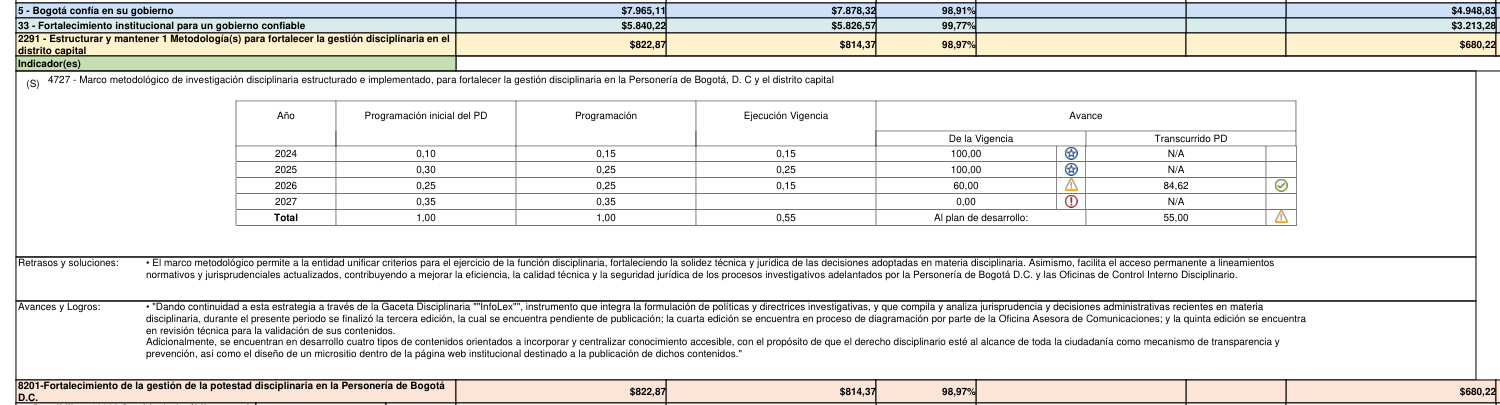

**Página 15, fragmento visual del reporte**

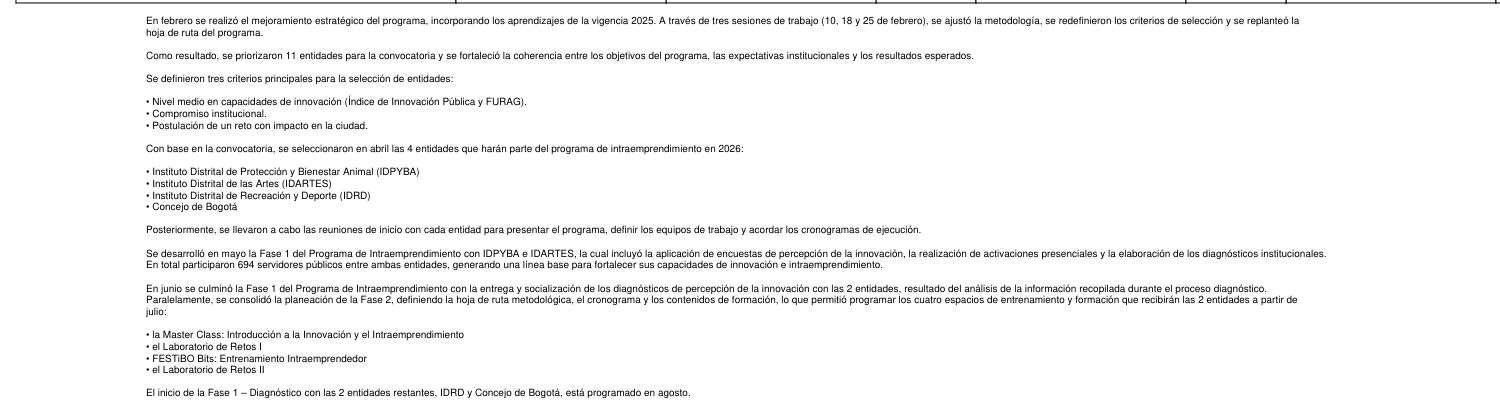

**Página 16, fragmento visual del reporte**

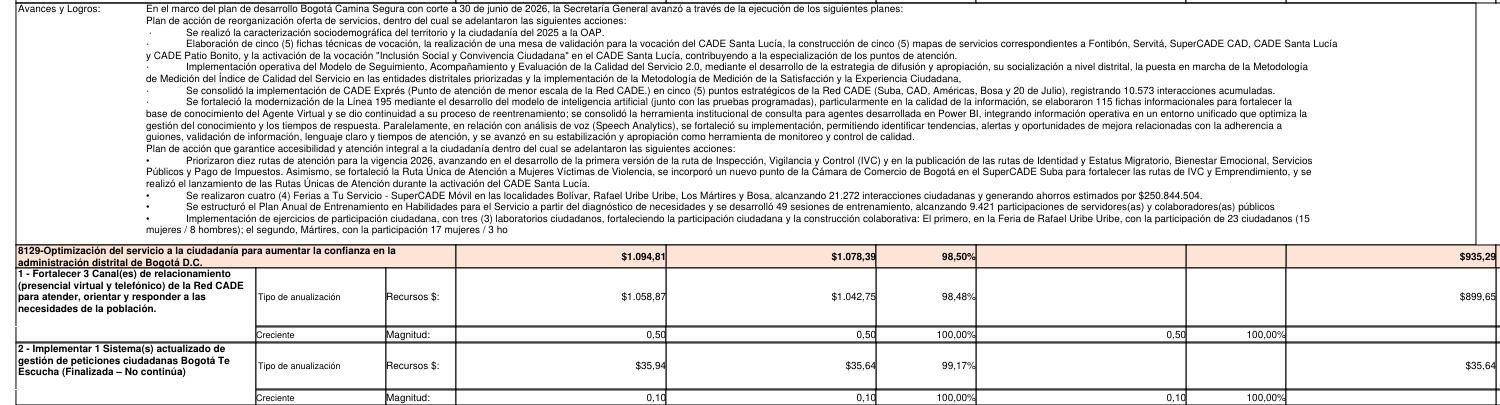

In [9]:
if FUENTE is not None:
    PAGINAS_REVISAR = [1, 15, 16]
    with pymupdf.open(FUENTE) as documento:
        for numero in PAGINAS_REVISAR:
            if numero > len(documento):
                continue
            clip = pymupdf.Rect(0, 245, 1500, 650)
            imagen = documento[numero - 1].get_pixmap(matrix=pymupdf.Matrix(1, 1), clip=clip)
            display(Markdown(f"**Página {numero}, fragmento visual del reporte**"))
            display(Image(data=imagen.tobytes("png")))


## 9. Cómo verifico la exportación y sus límites

Exporto la base de tres campos con punto y coma, comillas y UTF-8 con BOM. La releo sin convertir marcadores literales en nulos y comparo todo su contenido. Exijo códigos de meta identificados y una fila física por meta, pero no obligo a que un campo narrativo tenga contenido si la fuente lo dejó vacío.

Compruebo que la huella del PDF siga intacta y muestro los controles dentro del notebook. La validación de cobertura se ejecuta antes de escribir: si el PDF y el catálogo no concuerdan, no entrego una extracción como completa.

El resultado conserva los límites de la fuente, depende de los perfiles visuales probados y prepara el material para su análisis posterior. No completa información ausente ni sustituye una codificación cualitativa.


In [10]:
if FUENTE is not None:
    DESTINO.mkdir(parents=True, exist_ok=True)
    temporal = None
    try:
        with NamedTemporaryFile(dir=DESTINO, suffix=".part", delete=False) as f:
            temporal = Path(f.name)
        narrativas.to_csv(temporal, index=False, sep=";", encoding="utf-8-sig", quoting=csv.QUOTE_ALL, na_rep="")
        vuelta = pd.read_csv(temporal, sep=";", encoding="utf-8-sig", dtype="string", keep_default_na=False)
        pd.testing.assert_frame_equal(narrativas, vuelta, check_exact=True)
        with temporal.open(encoding="utf-8-sig", newline="") as f:
            filas = list(csv.reader(f, delimiter=";", strict=True))
        assert narrativas.notna().all().all()
        assert narrativas.PLAN_META_PRODUCTO_CODIGO.ne("").all()
        assert not narrativas.apply(lambda col: col.str.contains(r"[\r\n]", regex=True)).any().any()
        assert len(temporal.read_text(encoding="utf-8-sig").splitlines()) == len(narrativas) + 1
        assert filas[0] == COLUMNAS_SALIDA
        assert len(filas) == len(narrativas) + 1 and all(len(fila) == 3 for fila in filas)
        temporal.replace(RUTA_CSV)
    finally:
        if temporal is not None:
            temporal.unlink(missing_ok=True)
    
    # Controles visibles en el notebook, sin exportar archivos auxiliares.
    assert hashlib.sha256(FUENTE.read_bytes()).hexdigest() == HUELLA
    control_exportacion = {
        "fuente": FUENTE.relative_to(RAIZ).as_posix(),
        "sha256_fuente": HUELLA,
        "sha256_csv": hashlib.sha256(RUTA_CSV.read_bytes()).hexdigest(),
        "fecha_corte": FECHA.isoformat(),
        "metas_exportadas": len(narrativas),
        "campos": COLUMNAS_SALIDA,
        "lineas_contrastadas": verificacion_independiente["lineas"],
        "diferencias_segundo_lector": len(verificacion_independiente["diferencias"])
    }
    display(control_exportacion)
    print("CSV:", RUTA_CSV.relative_to(RAIZ))
    print("Filas:", len(narrativas), "| Columnas:", list(narrativas.columns))
    print("Bronce intacta. Se generan solamente el CSV y el Excel de narrativas.")


{'fuente': 'Capa Bronce/2026-06-30/gestion_inversion/planacciongestioninversion20260630_entidades_a2ddd1077b.pdf',
 'sha256_fuente': 'c473c0b452ddf172d03af549ae7f86ca8315247cfaeed9090f8b7b27c61865b3',
 'sha256_csv': '99a68222a0b8a868557b03fff0b5e14038ebcb5167afa5b491b058d9f13cf12c',
 'fecha_corte': '2026-06-30',
 'metas_exportadas': 425,
 'campos': ['PLAN_META_PRODUCTO_CODIGO',
  'RETRASOS_Y_SOLUCIONES',
  'AVANCES_Y_LOGROS'],
 'lineas_contrastadas': 7363,
 'diferencias_segundo_lector': 0}

CSV: Capa Silver\2026-06-30\gestion_inversion\gestion_inversion_narrativas.csv
Filas: 425 | Columnas: ['PLAN_META_PRODUCTO_CODIGO', 'RETRASOS_Y_SOLUCIONES', 'AVANCES_Y_LOGROS']
Bronce intacta. Se generan solamente el CSV y el Excel de narrativas.


## 10. Cómo presento el Excel de revisión

Genero un Excel con los mismos tres campos y valores del CSV, códigos como texto y filtros. Mantengo las funciones técnicas al final para que la lectura del documento siga el orden de exploración, decisión y comprobación.

Conservo los textos completos. La altura visible de una fila de Excel tiene un límite de 409 puntos; si un relato no cabe visualmente, puedo consultarlo en la barra de fórmulas o en el CSV. No interpreto ese límite visual como un truncamiento del contenido guardado.


### Funciones auxiliares de exportación

En el bloque siguiente reúno las funciones que utilizo para escribir Excel. Mantengo identificadores como texto, cadenas literales y el contenido completo de las celdas. En Gestión-Inversión compruebo además que la copia nativa del diccionario conserve su presentación y sus valores. Ubico estas funciones después del análisis para facilitar la lectura metodológica.


In [11]:
from collections import OrderedDict
from datetime import date, datetime
from pathlib import Path
from tempfile import NamedTemporaryFile
import math
import os
import textwrap

def _valor_excel(valor):
    import pandas as pd
    if valor is None or pd.isna(valor):
        return None
    if hasattr(valor, "item"):
        valor = valor.item()
    if isinstance(valor, (datetime, date)):
        return valor.strftime("%Y-%m-%d")
    if isinstance(valor, float) and not math.isfinite(valor):
        raise ValueError("No se exportan números infinitos a Excel.")
    if isinstance(valor, str) and len(valor) > 32767:
        raise ValueError("Una celda supera el límite de 32.767 caracteres de Excel; no se trunca el texto.")
    return valor

def _lineas(texto, ancho):
    partes = str(texto or "").splitlines() or [""]
    return sum(max(1, len(textwrap.wrap(p, width=ancho))) for p in partes)

def exportar_excel(ruta, hojas, *, sin_encabezado=()):
    """Exporta DataFrames o listas de filas con openpyxl (Windows/macOS/Linux).

    Los identificadores permanecen como texto y las cadenas nunca se interpretan
    como fórmulas. No trunca valores para ajustarlos a una altura visible de fila.
    """
    from openpyxl import Workbook
    from openpyxl.styles import Alignment, Font, PatternFill
    from openpyxl.worksheet.table import Table, TableStyleInfo

    ruta = Path(ruta)
    ruta.parent.mkdir(parents=True, exist_ok=True)
    libro = Workbook()
    libro.remove(libro.active)
    azul = "17365D"
    verde = "26734D"
    for indice, (nombre, datos) in enumerate(OrderedDict(hojas).items(), start=1):
        hoja = libro.create_sheet(nombre)
        if hasattr(datos, "itertuples"):
            filas = list(datos.itertuples(index=False, name=None))
            if nombre not in sin_encabezado:
                filas.insert(0, list(datos.columns))
        else:
            filas = list(datos)
        for fila in filas:
            hoja.append([_valor_excel(v) for v in fila])
        # Algunas cadenas narrativas comienzan con signos: Excel debe conservarlas literalmente.
        for fila in hoja:
            for celda in fila:
                celda.font = Font(name="Calibri", size=11)
                celda.alignment = Alignment(vertical="top", wrap_text=True)
                if isinstance(celda.value, str):
                    celda.data_type = "s"
        if not filas:
            continue
        if nombre in sin_encabezado:
            for letra, ancho in {"A": 48, "B": 65, "C": 20, "D": 95, "E": 95}.items():
                hoja.column_dimensions[letra].width = ancho
            for fila in hoja:
                hoja.row_dimensions[fila[0].row].height = 95
            for celda in hoja[6]:
                celda.fill = PatternFill("solid", fgColor=azul)
                celda.font = Font(name="Calibri", size=11, bold=True, color="FFFFFF")
            hoja.freeze_panes = "A7"
            hoja.row_dimensions[6].height = 40
            continue
        encabezados = [str(c.value) for c in hoja[1]]
        es_narrativa = encabezados == ["PLAN_META_PRODUCTO_CODIGO", "RETRASOS_Y_SOLUCIONES", "AVANCES_Y_LOGROS"]
        for celda in hoja[1]:
            celda.fill = PatternFill("solid", fgColor=verde if celda.value.startswith("AJUSTE_") or celda.value.endswith(("_NORMALIZADO", "_PORCGIROS_SOBRE_PROGRAMADO")) else azul)
            celda.font = Font(name="Calibri", size=11, bold=True, color="FFFFFF")
            hoja.column_dimensions[celda.column_letter].width = 32
            if celda.value.endswith("_CODIGO") or celda.value == "PROYECTO_BPIN":
                for fila in hoja.iter_rows(min_row=2, min_col=celda.column, max_col=celda.column):
                    fila[0].number_format = "@"
            if "_NOMBRE" in celda.value or celda.value.startswith("AJUSTE_"):
                hoja.column_dimensions[celda.column_letter].width = 65
        if es_narrativa:
            for letra, ancho in {"A": 21, "B": 72, "C": 142}.items():
                hoja.column_dimensions[letra].width = ancho
            hoja.row_dimensions[1].height = 48
            for i, fila in enumerate(filas[1:], start=2):
                alto = max(_lineas(fila[1], 86), _lineas(fila[2], 172)) * 14 + 10
                hoja.row_dimensions[i].height = min(409, max(30, alto))
        elif nombre == "Diccionario":
            for celda in hoja[1]:
                hoja.column_dimensions[celda.column_letter].width = 75 if celda.column >= 5 else 45
            hoja.row_dimensions[1].height = 48
            for i in range(2, hoja.max_row + 1):
                hoja.row_dimensions[i].height = 210
        else:
            hoja.row_dimensions[1].height = 105
            hoja.sheet_format.defaultRowHeight = 24
        if hoja.max_row > 1:
            tabla = Table(displayName=f"Tabla_{indice}", ref=hoja.dimensions)
            tabla.tableStyleInfo = TableStyleInfo(name="TableStyleMedium2", showRowStripes=True)
            hoja.add_table(tabla)
        hoja.freeze_panes = "A2"
    temporal = None
    try:
        with NamedTemporaryFile(dir=ruta.parent, suffix=".xlsx", delete=False) as archivo:
            temporal = Path(archivo.name)
        libro.save(temporal)
        os.replace(temporal, ruta)
    finally:
        libro.close()
        if temporal is not None:
            temporal.unlink(missing_ok=True)
    return ruta


### Generación del libro de revisión

En esta última celda aplico las funciones anteriores a la tabla narrativa ya validada. Guardo los mismos campos del CSV y muestro las rutas para revisar el resultado.


In [12]:
if FUENTE is not None:
    RUTA_EXCEL = DESTINO / "gestion_inversion_narrativas.xlsx"
    exportar_excel(RUTA_EXCEL, {"Narrativas_por_meta": narrativas})
    print("Excel:", RUTA_EXCEL.relative_to(RAIZ))
    print("CSV y Excel contienen las mismas metas y los mismos tres campos.")


Excel: Capa Silver\2026-06-30\gestion_inversion\gestion_inversion_narrativas.xlsx
CSV y Excel contienen las mismas metas y los mismos tres campos.


## 11. Alcance de la actualización narrativa

Los conteos y conclusiones se recalculan desde el PDF seleccionado. Si falta el documento del corte omito la etapa y no traslado resultados narrativos de otro periodo. Un PDF disponible todavía debe superar reconocimiento, cobertura y fidelidad antes de exportar.

Los perfiles probados y las revisiones anteriores quedan identificados en el anexo histórico. No convierto la ausencia de vacíos, una cobertura compatible o la coincidencia entre lectores de otra publicación en una condición ya satisfecha para esta.



---

<details>
<summary>Anexo histórico: evidencias y redacción de las revisiones anteriores — no describe el corte seleccionado</summary>

Conservo estos textos como registro de revisiones puntuales, realizadas sobre las fuentes y fechas que cada apartado identifica. Sus conteos, ejemplos, resultados y límites pertenecen a esas versiones. No son resultados recalculados ni condiciones satisfechas para una nueva ejecución. La metodología operativa y los informes del corte seleccionado están en el cuerpo principal. Las revisiones históricas no se amplían automáticamente.

# Exploración documental y extracción verificable de narrativas

## Propósito y unidad de presentación

En este notebook recupero retrasos/soluciones y avances/logros del PDF oficial y preparo una fila por meta producto. Primero reconstruyo los reportes de entidad, meta e indicador para preservar su contexto y las continuaciones entre páginas; solo después agrupo los textos para la salida solicitada.

Revisé los cuatro PDF por entidades de BCS publicados en el catálogo consultado: septiembre y diciembre de 2024 y marzo y junio de 2026. No supuse que todo corte numérico tuviera PDF narrativo. Tampoco tomé una extracción de palabras correcta como prueba suficiente de que hubiera cobertura completa de indicadores.

**Periodo de la revisión.** Realicé la revisión histórica el 29 de octubre de 2026 con las versiones que el catálogo de la SDP ofrecía ese día. Distingo el corte de la publicación, la fecha de la observación y la versión del archivo. Las cifras históricas de este texto son resultados de esa revisión; las tablas ejecutables se recalculan para la fuente seleccionada. No atribuyo las conclusiones de un archivo a periodos futuros sin repetir los controles.

Mi alcance es preparar y verificar la extracción. No resumo relatos, no completo frases, no adjudico veracidad a las declaraciones institucionales y no realizo codificación temática en esta etapa.


---

## 2. Por qué utilizo la estructura visual del documento

La inspección mostró que el orden del texto extraído no siempre coincide con el orden visual. Por eso transformo las coordenadas de página y reconozco posiciones de metas, indicadores, etiquetas y cuerpos narrativos. Una expresión regular entre dos palabras no basta para asignar los relatos.

La revisión de 2024 también mostró un diseño de 1.620 × 1.500 puntos, además del formato de 7.320 × 2.000 de los otros reportes. Incorporé ambos perfiles, sus límites de datos y las posiciones observadas. En un diseño no reconocido detengo la lectura. No aplico una escala geométrica inventada a cualquier PDF futuro.

Recorro todas las páginas para verificar texto, corte, identidad del plan y encabezados de entidad. Cuento las etiquetas estructurales por posición, no cualquier mención literal dentro de un relato. Esta última distinción corrigió un falso desacuerdo que apareció al probar marzo de 2026.


---

## 3. Cómo reconstruyo cada reporte

Mantengo el estado del campo narrativo entre páginas y cierro el bloque cuando aparece otra sección o cambia el reporte. Registro qué líneas utilicé y compruebo que no asigne una misma línea a dos campos. También verifico que cada bloque tenga las dos etiquetas solicitadas.

En 2024 encontré dos bloques sin código de indicador impreso. Los conservo vinculados a su entidad y meta, dejando ausente ese código; no lo completo usando un catálogo posterior. Esta ausencia se cuenta y se considera al validar cobertura.

La celda siguiente implementa la jerarquía reconocida. Si encuentro una transición ambigua o una etiqueta incompleta, detengo el proceso para evitar mezclar relatos.


---

### Qué encontré al reconocer los reportes

En junio de 2026 reconstruí 517 reportes de 48 entidades a partir de 264 páginas. Identifiqué 51 reportes con texto repartido entre páginas; esa evidencia justificó conservar el estado de lectura en lugar de procesar cada página de forma independiente.

Los conteos se obtienen del archivo y no se fijan como constantes. En marzo de 2026 encontré 515 reportes; en cada uno de los dos PDF de 2024 reconstruí 514, con dos bloques sin código de indicador impreso. El número de reportes no equivale al de indicadores distintos porque varias entidades pueden referirse a un mismo indicador.


---

## 4. Cómo distingo extracción correcta y cobertura de la fuente

Comparo los pares meta–indicador impresos con Avance del Plan del mismo corte y verifico que ambos pertenezcan al mismo plan. Si falta un código de indicador en un bloque, valido su meta sin inventar el código. También contrasto entidad–meta con Gestión-Inversión cuando está disponible.

La comparación mostró que los PDF de septiembre y diciembre de 2024 no explican el par `2296–4726` que aparece en el Excel de Avance. Inspeccioné las apariciones de la meta y comprobé la ausencia de ese código impreso en esos reportes. No trasladé un relato de la meta 2305 a la 2296 ni fabriqué la relación para hacer coincidir los conteos.

Mantengo el control estricto antes de exportar: esos dos cortes requieren resolver la discrepancia de fuente. La revisión externa de su extracción textual pudo continuar para diagnosticarla, pero no se presentó como una exportación validada del flujo completo. En marzo y junio de 2026 el contraste pasó.

No uno directamente los relatos con cada actividad financiera, porque multiplicaría textos y montos. Primero verifico cobertura y después preparo la unidad cualitativa solicitada.


---

### Cómo interpreté el diagnóstico del corte local

En junio de 2026 encontré 1.034 campos narrativos, sin vacíos. Conté 2 campos con `0`, 15 con `NA`, 7 con `N/A` y 2 con `No aplica`; los conservé como respuestas literales. Señalé 21 campos de avances de al menos 3.995 caracteres para revisar sus finales, sin afirmar que todos estén truncados.

La revisión histórica impidió convertir la ausencia de vacíos de junio en una regla general: los PDF de 2024 incluyen campos sin contenido. Por eso la exportación conserva un texto vacío legítimo y solo exige que la meta esté identificada y que el contenido sobreviva a la lectura de vuelta.


---

### Qué cambió al preparar la unidad de salida

Para junio de 2026 pasé de 517 reportes a 425 metas y tres campos. Omití tres repeticiones exactas en retrasos/soluciones y ninguna en avances/logros. Esta reducción responde a la unidad de presentación y a una regla de igualdad textual localizada, no a una eliminación de reportes por considerarlos poco informativos.

Conservo los textos semejantes y las posibles limitaciones de la fuente. La tabla siguiente muestra una vista de revisión, sin resumir los relatos extensos.


---

### Qué alcance tiene el resultado del segundo lector

En junio de 2026 contrasté 7.363 líneas narrativas de 246 páginas sin diferencias de presencia textual bajo la normalización descrita. El inventario inicial recorrió las 264 páginas: las 246 corresponden a páginas con líneas narrativas seleccionadas.

También realicé el contraste sobre los otros tres PDF disponibles. Que sus palabras se conserven no resuelve la discrepancia de cobertura de los dos reportes de 2024. Mantengo ambas conclusiones separadas en la tabla histórica final.


---

## 8. Por qué reviso muestras visuales

Reviso muestras del primer bloque y de continuaciones para contrastar etiquetas, límites y asignación. Esta revisión responde al riesgo de conservar correctamente las palabras y asociarlas al campo equivocado.

Las muestras complementan los controles geométricos y textuales. No las presento como una lectura manual exhaustiva de cada relato de las 264 páginas del corte local.


---

## 11. Qué pude validar en los PDF históricos

Recorrí íntegramente los cuatro documentos y contrasté sus líneas narrativas con un segundo lector. La comprobación de cobertura se interpreta por separado. Los campos vacíos se cuentan antes de agrupar.

| Corte y fuente oficial | Páginas | Reportes | Sin código de indicador | Campos vacíos | Líneas contrastadas | Cobertura frente a Avance |
|---|---:|---:|---:|---:|---:|---|
| [2024-09-30](https://www.sdp.gov.co/sites/default/files/componentegestioninversionbcs20240930.pdf) | 329 | 514 | 2 | 116 | 3802 | Requiere revisar el par 2296–4726 |
| [2024-12-31](https://www.sdp.gov.co/sites/default/files/pa_cg_ci_20241231_entidad.pdf) | 247 | 514 | 2 | 4 | 5839 | Requiere revisar el par 2296–4726 |
| [2026-03-31](https://www.sdp.gov.co/sites/default/files/planacciongestioninversionentidad20260331_ver20260430.pdf) | 251 | 515 | 0 | 0 | 6356 | Compatible |
| [2026-06-30](https://www.sdp.gov.co/sites/default/files/planacciongestioninversion20260630_entidades.pdf) | 264 | 517 | 0 | 0 | 7363 | Compatible |

Las cuatro extracciones conservaron las líneas contrastadas sin diferencias de presencia textual. En 2024 pude reconstruir 425 metas, pero ese conteo por sí solo no resuelve una correspondencia de indicadores faltante. Por eso no relajé el control solo para obtener un resultado exitoso.

No encontré un PDF de Gestión-Inversión por entidades enlazado en las publicaciones de 2025 ni en septiembre de 2026 del catálogo consultado. No atribuyo a esos cortes resultados narrativos de otro periodo. Su limpieza numérica sí se prueba en 02 y 03.


</details>
